In [53]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, make_scorer

In [54]:
feature_names = [
    "id", "diagnosis", "radius_mean", "texture_mean", "perimeter_mean", "area_mean",
    "smoothness_mean", "compactness_mean", "concavity_mean", "concave points_mean",
    "symmetry_mean", "fractal_dimension_mean", "radius_se", "texture_se", "perimeter_se",
    "area_se", "smoothness_se", "compactness_se", "concavity_se", "concave points_se",
    "symmetry_se", "fractal_dimension_se", "radius_worst", "texture_worst",
    "perimeter_worst", "area_worst", "smoothness_worst", "compactness_worst",
    "concavity_worst", "concave points_worst", "symmetry_worst", "fractal_dimension_worst"
]

df = pd.read_csv("data.csv", header=None, names=feature_names)

print("Dataset shape:", df.shape)
df

Dataset shape: (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [55]:
df = df.drop(columns=['id'])

In [56]:
x = df.drop(columns=['diagnosis'])
y = df['diagnosis']

print("Features:", x.shape)
print("Target:", y.shape)

Features: (569, 30)
Target: (569,)


In [60]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [61]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("Training data:", x_train_scaled.shape)
print("Testing data:", x_test_scaled.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [62]:
svm = SVC(random_state=42)
svm.fit(x_train_scaled, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [63]:
y_pred_svm = svm.predict(x_test_scaled)
print("SVM model trained")

SVM model trained


In [64]:
acc_svm = accuracy_score(y_test, y_pred_svm)
prec_svm = precision_score(y_test, y_pred_svm, pos_label="M")
rec_svm = recall_score(y_test, y_pred_svm, pos_label="M")
f1_svm = f1_score(y_test, y_pred_svm, pos_label="M")

print("SVM Performance Before Optimization\n")
print("Accuracy:", acc_svm)
print("Precision:", prec_svm)
print("Recall:", rec_svm)
print("F1-Score:", f1_svm)

SVM Performance Before Optimization

Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1-Score: 0.9629629629629629


In [65]:
f1_scorer = make_scorer(f1_score, pos_label="M")
scores_svm = cross_val_score(svm, x_train_scaled, y_train, cv=5, scoring=f1_scorer)

print("SVM Cross-Validation Scores:", scores_svm)
print("Mean CV F1 score:", scores_svm.mean())

SVM Cross-Validation Scores: [0.95384615 1.         0.95384615 0.95652174 0.97058824]
Mean CV F1 score: 0.966960456423372


In [66]:
param_grid_svm = {
    "C": [0.1, 1, 10, 100],
    "kernel": ["rbf", "linear", "poly"],
    "gamma": ["scale", "auto", 0.01, 0.1]
}

In [67]:
grid_svm = GridSearchCV(SVC(),param_grid_svm,cv=5,scoring=f1_scorer,n_jobs=-1)

In [68]:
grid_svm.fit(x_train_scaled, y_train)

,estimator,SVC()
,param_grid,"{'C': [0.1, 1, ...], 'gamma': ['scale', 'auto', ...], 'kernel': ['rbf', 'linear', ...]}"
,scoring,"make_scorer(f..., pos_label=M)"
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,C,1


In [69]:
print("Best Parameters:", grid_svm.best_params_)
print("Best CV F1-Score:", grid_svm.best_score_)

Best Parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV F1-Score: 0.966960456423372


In [20]:
best_svm = grid_svm.best_estimator_

y_pred_svm_opt = best_svm.predict(x_test_scaled)

print("SVM Performance After Optimization\n")
print("Accuracy:", accuracy_score(y_test, y_pred_svm_opt))
print("Precision:", precision_score(y_test, y_pred_svm_opt, pos_label="M"))
print("Recall:", recall_score(y_test, y_pred_svm_opt, pos_label="M"))
print("F1-Score:", f1_score(y_test, y_pred_svm_opt, pos_label="M"))

SVM Performance After Optimization

Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1-Score: 0.9629629629629629


In [21]:
rf = RandomForestClassifier(random_state=42)
rf.fit(x_train_scaled, y_train)


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [22]:
y_pred_rf = rf.predict(x_test_scaled)
print("Random Forest model trained")

Random Forest model trained


In [23]:
acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf, pos_label="M")
recall_rf = recall_score(y_test, y_pred_rf, pos_label="M")
f1_rf = f1_score(y_test, y_pred_rf, pos_label="M")

print("Random Forest Performance Before Optimization")
print("Accuracy:", acc_rf)
print("Precision:", prec_rf)
print("Recall:", recall_rf)
print("F1-Score:", f1_rf)

Random Forest Performance Before Optimization
Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1-Score: 0.9629629629629629


In [24]:
scores_rf = cross_val_score(rf, x_train_scaled, y_train, cv=5, scoring=f1_scorer)

print("Random Forest Cross-Validation F1 Scores:", scores_rf)
print("Mean CV F1-Score:", scores_rf.mean())

Random Forest Cross-Validation F1 Scores: [1.         0.98507463 0.90909091 0.97058824 0.88571429]
Mean CV F1-Score: 0.9500936113929968


In [35]:
param_grid_rf = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10],
    "criterion": ["gini", "entropy"],
    "min_samples_split": [2, 5, 10]
}

In [36]:
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=5, scoring=f1_scorer, n_jobs=-1)

In [37]:
grid_rf.fit(x_train_scaled, y_train)

,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [None, 5, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [50, 100, ...]}"
,scoring,"make_scorer(f..., pos_label=M)"
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,50


In [38]:
print("Best Parameters:", grid_rf.best_params_)
print("Best CV F1-Score:", grid_rf.best_score_)

Best Parameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Best CV F1-Score: 0.9561297227052954


In [39]:
best_rf = grid_rf.best_estimator_

y_pred_rf_opt = best_rf.predict(x_test_scaled)

print("Random Forest Performance After Optimization\n")
print("Accuracy:", accuracy_score(y_test, y_pred_rf_opt))
print("Precision:", precision_score(y_test, y_pred_rf_opt, pos_label="M"))
print("Recall:", recall_score(y_test, y_pred_rf_opt, pos_label="M"))
print("F1-Score:", f1_score(y_test, y_pred_rf_opt, pos_label="M"))

Random Forest Performance After Optimization

Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1-Score: 0.9629629629629629


In [40]:
ada = AdaBoostClassifier(random_state=42)
ada.fit(x_train_scaled, y_train)

,estimator,None
,n_estimators,50
,learning_rate,1.0
,algorithm,'deprecated'
,random_state,42


In [41]:
y_pred_ada = ada.predict(x_test_scaled)
print("AdaBoost model trained")

AdaBoost model trained


In [42]:
acc_ada = accuracy_score(y_test, y_pred_ada)
prec_ada = precision_score(y_test, y_pred_ada, pos_label="M")
recall_ada = recall_score(y_test, y_pred_ada, pos_label="M")
f1_ada = f1_score(y_test, y_pred_ada, pos_label="M")

print("AdaBoost Performance Before Optimization\n")
print("Accuracy:", acc_ada)
print("Precision:", prec_ada)
print("Recall:", recall_ada)
print("F1-Score:", f1_ada)

AdaBoost Performance Before Optimization

Accuracy: 0.9824561403508771
Precision: 1.0
Recall: 0.9523809523809523
F1-Score: 0.975609756097561


In [43]:
scores_ada = cross_val_score(ada, x_train_scaled, y_train, cv=5, scoring=f1_scorer)

print("AdaBoost Cross-Validation F1 Scores:", scores_ada)
print("Mean CV F1-Score:", scores_ada.mean())

AdaBoost Cross-Validation F1 Scores: [0.96969697 0.98507463 0.89552239 0.98507463 0.90909091]
Mean CV F1-Score: 0.9488919041157848


In [44]:
param_grid_ada = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.01, 0.1, 1.0]
}

In [45]:
grid_ada = GridSearchCV(
    AdaBoostClassifier(random_state=42),
    param_grid_ada,
    cv=5,
    scoring=f1_scorer,
    n_jobs=-1
)

grid_ada.fit(x_train_scaled, y_train)

print("Best Parameters:", grid_ada.best_params_)
print("Best CV F1-Score:", grid_ada.best_score_)

Best Parameters: {'learning_rate': 1.0, 'n_estimators': 200}
Best CV F1-Score: 0.9524117381009392


In [46]:
best_ada = grid_ada.best_estimator_

y_pred_ada_opt = best_ada.predict(x_test_scaled)

print("AdaBoost Performance After Optimization\n")
print("Accuracy:", accuracy_score(y_test, y_pred_ada_opt))
print("Precision:", precision_score(y_test, y_pred_ada_opt, pos_label="M"))
print("Recall:", recall_score(y_test, y_pred_ada_opt, pos_label="M"))
print("F1-Score:", f1_score(y_test, y_pred_ada_opt, pos_label="M"))

AdaBoost Performance After Optimization

Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1-Score: 0.9629629629629629


In [48]:
comparison = pd.DataFrame({
    "Model": ["SVM", "Random Forest", "AdaBoost"],

    "Accuracy Before": [
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_ada)
    ],

    "Accuracy After": [
        accuracy_score(y_test, y_pred_svm_opt),
        accuracy_score(y_test, y_pred_rf_opt),
        accuracy_score(y_test, y_pred_ada_opt)
    ],

    "Precision Before": [
        precision_score(y_test, y_pred_svm, pos_label="M"),
        precision_score(y_test, y_pred_rf, pos_label="M"),
        precision_score(y_test, y_pred_ada, pos_label="M")
    ],

    "Precision After": [
        precision_score(y_test, y_pred_svm_opt, pos_label="M"),
        precision_score(y_test, y_pred_rf_opt, pos_label="M"),
        precision_score(y_test, y_pred_ada_opt, pos_label="M")
    ],

    "Recall Before": [
        recall_score(y_test, y_pred_svm, pos_label="M"),
        recall_score(y_test, y_pred_rf, pos_label="M"),
        recall_score(y_test, y_pred_ada, pos_label="M")
    ],

    "Recall After": [
        recall_score(y_test, y_pred_svm_opt, pos_label="M"),
        recall_score(y_test, y_pred_rf_opt, pos_label="M"),
        recall_score(y_test, y_pred_ada_opt, pos_label="M")
    ],

    "F1-Score Before": [
        f1_score(y_test, y_pred_svm, pos_label="M"),
        f1_score(y_test, y_pred_rf, pos_label="M"),
        f1_score(y_test, y_pred_ada, pos_label="M")
    ],

    "F1-Score After": [
        f1_score(y_test, y_pred_svm_opt, pos_label="M"),
        f1_score(y_test, y_pred_rf_opt, pos_label="M"),
        f1_score(y_test, y_pred_ada_opt, pos_label="M")
    ]
})

print("Model Performance Comparison: Before vs After Optimization\n")
display(comparison.round(4))

Model Performance Comparison: Before vs After Optimization



,Model,Accuracy Before,Accuracy After,Precision Before,Precision After,Recall Before,Recall After,F1-Score Before,F1-Score After
0,SVM,0.9737,0.9737,1.0,1.0,0.9286,0.9286,0.9630,0.963
1,Random Forest,0.9737,0.9737,1.0,1.0,0.9286,0.9286,0.9630,0.963
2,AdaBoost,0.9825,0.9737,1.0,1.0,0.9524,0.9286,0.9756,0.963


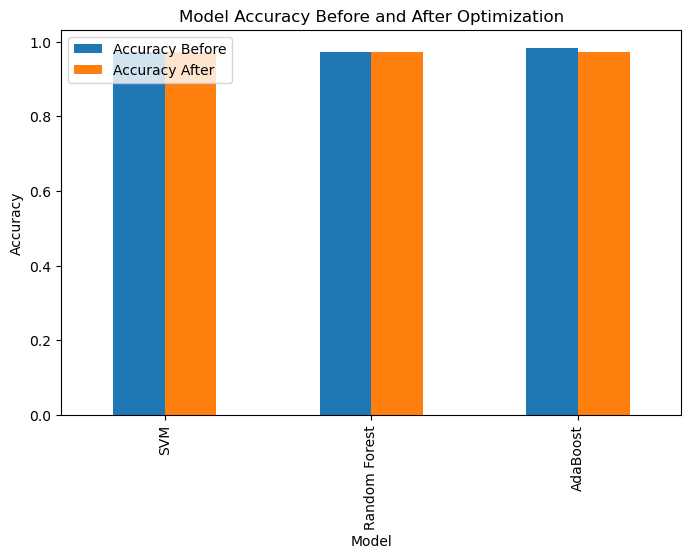

In [73]:
import matplotlib.pyplot as plt

comparison.set_index("Model")[["Accuracy Before", "Accuracy After"]].plot(kind="bar", figsize=(8,5))

plt.title("Model Accuracy Before and After Optimization")
plt.ylabel("Accuracy")
plt.legend(loc="upper left")
plt.show()